# 00 从这里开始：一张图片怎样成为计算机里的数值

目标：确认环境，读入真实图片，把像素转为矩阵，执行一次 CPU/GPU 兼容计算。
先阅读项目根目录 README，安装完成后，选择 Python 内核，点击“运行 → 运行所有单元格”。
每一课都可以在新内核中独立运行；不要把安装命令混在算法单元中。


In [1]:
from pathlib import Path
import sys
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").exists()), None)
if root is None:
    raise RuntimeError("请在完整的 cv-beginner-course 项目里打开 Notebook")
if str(root) not in sys.path: sys.path.insert(0, str(root))
from course_utils import setup, device, show_images, save_figure, ROOT
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
print("计算设备:", device())


计算设备: cpu


## 1 输入：项目自带的真实照片
图片来自 OpenCV 官方样例，下载来源和校验值见 assets/SOURCES.json。读取失败时立即报错，避免悄悄把随机图当成照片。


H,W,C= (480, 512, 3) 类型= uint8 范围= (np.uint8(0), np.uint8(252))


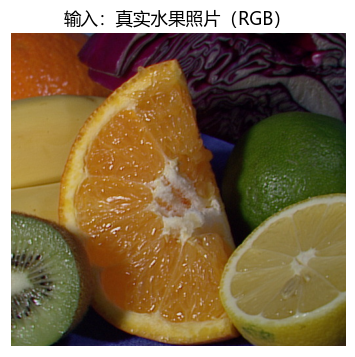

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/00_input_photo.png')

In [2]:
path = ROOT / "assets/photos/fruits.jpg"
bgr = cv2.imread(str(path))
if bgr is None: raise FileNotFoundError(path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("H,W,C=", rgb.shape, "类型=", rgb.dtype, "范围=", (rgb.min(), rgb.max()))
show_images([rgb], ["输入：真实水果照片（RGB）"])
save_figure("00_input_photo")


## 2 一个像素与一个局部矩阵
RGB 像素有三个通道。`rgb[y, x]` 表示第 y 行、第 x 列；OpenCV 读入时通道顺序是 BGR，显示前转换。


左上像素 RGB: [130  62  13]
红通道左上 5×5 矩阵:
 [[130 131 134 134 134]
 [137 137 137 136 134]
 [139 138 138 136 136]
 [141 140 138 136 137]
 [145 143 141 139 139]]
8×8灰度矩阵:
 [[ 81  56  31  49  38  25  13  32]
 [108  91  99 122  42  29  30  44]
 [148 140 130 114  55  21  50  43]
 [144 145 121 130  69  38  72  59]
 [122 137 126 131 114  39 105 118]
 [102  81  95 116 112  99 127 122]
 [100  82  67 107 112 132 119 113]
 [103  44  45 124 119  95 110  88]]


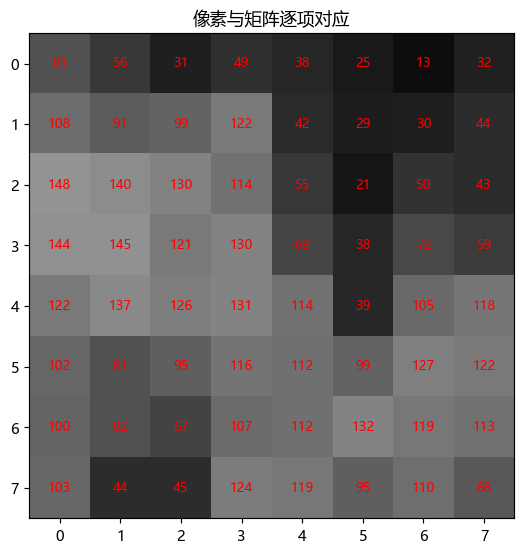

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/00_pixel_matrix.png')

In [3]:
print("左上像素 RGB:", rgb[0, 0])
print("红通道左上 5×5 矩阵:\n", rgb[:5, :5, 0])
gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
small = cv2.resize(gray, (8, 8), interpolation=cv2.INTER_AREA)
print("8×8灰度矩阵:\n", small)
fig, ax = plt.subplots(figsize=(6, 6)); ax.imshow(small, cmap="gray", vmin=0, vmax=255)
for y in range(8):
    for x in range(8): ax.text(x, y, str(small[y,x]), ha="center", va="center", color="red", fontsize=9)
ax.set_title("像素与矩阵逐项对应"); save_figure("00_pixel_matrix")


## 3 过程：数组变成张量
图像常为 H×W×C，PyTorch 卷积输入为 N×C×H×W。`N` 是批量大小，像素除以 255 后处于 [0,1]。


输入张量: (1, 3, 480, 512) cpu 输出: (480, 512, 3)


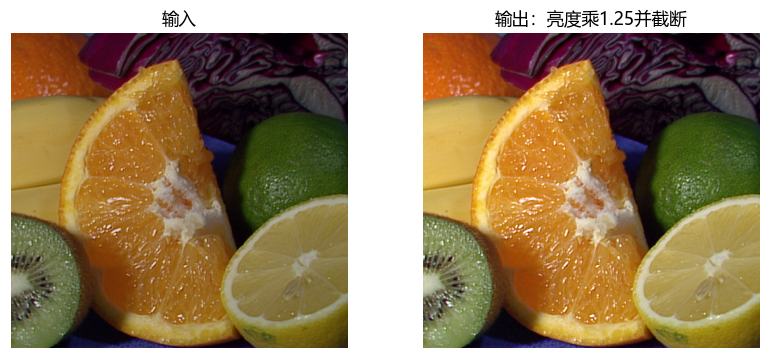

In [4]:
x = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().unsqueeze(0) / 255
x = x.to(device())
bright = (x * 1.25).clamp(0, 1)
output = bright[0].detach().cpu().permute(1, 2, 0).numpy()
print("输入张量:", tuple(x.shape), x.device, "输出:", output.shape)
show_images([rgb, output], ["输入", "输出：亮度乘1.25并截断"])
save_figure("00_input_output")
assert x.ndim == 4 and np.isfinite(output).all()


## 4 自己做
1. 把系数改成 0.6，再检查三个像素的前后变化。
2. 把图片替换为自己拍摄的照片，观察 H、W 是否改变。
3. 修改环境变量 `CV_DEVICE=cpu` 可以强制 CPU；默认自动选用 CUDA/MPS/CPU。

本机仅验证 CPU。GPU 代码使用相同算法、张量和设备迁移，实际 GPU 速度仍需在有显卡的机器测量。
下一课：01 中手算采样、量化和颜色转换。来源：[OpenCV 图像入门](https://docs.opencv.org/4.x/d3/df2/tutorial_py_basic_ops.html)、[PyTorch 张量](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)。
